# Google Play Store Apps - Exploratory Data Analysis (EDA)
**App Insights Unlocked: A Data Analytics Challenge**

**Prepared by:** Shubham Shah  
**Tools used:** Python, NumPy, Pandas, Matplotlib

## Project Overview
I am working as a data analyst for a company that builds mobile apps. The company has bought the Google Play Store dataset and wants to know what makes an app successful, which categories are popular, and how app size and price are related to ratings, reviews and installs.

**Questions I want to answer**
1. What are the key factors behind an app's success on the Play Store?
2. How can the company use these factors to improve its own apps?
3. What can we learn about user preferences and behaviour?

**Dataset:** Google Play Store Apps (Kaggle) - only `googleplaystore.csv` is used.  
Keep the csv file in the same folder as this notebook (or change the path in the load cell).

## Step 1: Import Libraries and Load the Data

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
df = pd.read_csv('googleplaystore.csv')

## Step 2: Understanding the Data

In [7]:
df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [8]:
df.tail()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10836,Sya9a Maroc - FR,FAMILY,4.5,38,53M,"5,000+",Free,0,Everyone,Education,"July 25, 2017",1.48,4.1 and up
10837,Fr. Mike Schmitz Audio Teachings,FAMILY,5.0,4,3.6M,100+,Free,0,Everyone,Education,"July 6, 2018",1.0,4.1 and up
10838,Parkinson Exercices FR,MEDICAL,NaN,3,9.5M,"1,000+",Free,0,Everyone,Medical,"January 20, 2017",1.0,2.2 and up
10839,The SCP Foundation DB fr nn5n,BOOKS_AND_REFERENCE,4.5,114,Varies with device,"1,000+",Free,0,Mature 17+,Books & Reference,"January 19, 2015",Varies with device,Varies with device
10840,iHoroscope - 2018 Daily Horoscope & Astrology,LIFESTYLE,4.5,398307,19M,"10,000,000+",Free,0,Everyone,Lifestyle,"July 25, 2018",Varies with device,Varies with device


In [9]:
df.shape

(10841, 13)

In [10]:
df.columns

Index(['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type',
       'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver',
       'Android Ver'],
      dtype='object')

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


In [12]:
df.describe(include='object')

,App,Category,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
count,10841,10841,10841,10841,10841,10840,10841,10840,10841,10841,10833,10838
unique,9660,34,6002,462,22,3,93,6,120,1378,2832,33
top,ROBLOX,FAMILY,0,Varies with device,"1,000,000+",Free,0,Everyone,Tools,"August 3, 2018",Varies with device,4.1 and up
freq,9,1972,596,1695,1579,10039,10040,8714,842,326,1459,2451


## Step 3: Data Cleaning
I clean the data in this order: duplicates, wrong row, data types, repeated apps, missing values, text.

### 3.1 Removing exact duplicate rows

In [15]:
# how many rows are fully duplicated
df.duplicated().sum()

483

In [16]:
df = df.drop_duplicates().copy()
df.shape

(10358, 13)

### 3.2 Removing the wrong row
One row in this file has all its values shifted by one column (its Category shows as `1.9`). It is not a real app record, so I remove it.

In [18]:
df[df['Category'] == '1.9']

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


In [19]:
df = df[df['Category'] != '1.9'].copy()
df.shape

(10357, 13)

### 3.3 Converting data types
Reviews, Installs, Price and Size are stored as text, so I convert them to numbers. `Last Updated` is converted to a date.

In [21]:
# Reviews: text -> number
df['Reviews'] = pd.to_numeric(df['Reviews'])

In [22]:
# Installs: '10,000+' -> 10000
df['Installs'] = df['Installs'].str.replace(',', '', regex=False).str.replace('+', '', regex=False)
df['Installs'] = pd.to_numeric(df['Installs'])

In [23]:
# Price: '$4.99' -> 4.99
df['Price'] = df['Price'].str.replace('$', '', regex=False)
df['Price'] = pd.to_numeric(df['Price'])

In [24]:
# Last Updated: text -> date
df['Last Updated'] = pd.to_datetime(df['Last Updated'])

In [25]:
# Size: look at the different formats first
df['Size'].str[-1].value_counts()

Size
M    8516
e    1526
k     315
Name: count, dtype: int64

In [26]:
# Size -> numeric column in MB ('k' is divided by 1024, 'Varies with device' becomes NaN)
def convert_size(size):
    if size.endswith('M'):
        return float(size[:-1])
    elif size.endswith('k'):
        return float(size[:-1]) / 1024
    else:
        return np.nan

df['Size_MB'] = df['Size'].apply(convert_size)
df[['Size', 'Size_MB']].head(10)

,Size,Size_MB
0,19M,19.0
1,14M,14.0
2,8.7M,8.7
3,25M,25.0
4,2.8M,2.8
5,5.6M,5.6
6,19M,19.0
7,29M,29.0
8,33M,33.0
9,3.1M,3.1


### 3.4 Removing repeated apps
Some apps still appear more than once (same app name, different review counts). I keep only one row per app - the one with the most reviews.

In [28]:
df['App'].duplicated().sum()

698

In [29]:
df = df.sort_values('Reviews', ascending=False)
df = df.drop_duplicates(subset='App', keep='first')
df = df.sort_index().reset_index(drop=True)
df.shape

(9659, 14)

### 3.5 Handling missing values

In [31]:
df.isnull().sum()

App                  0
Category             0
Rating            1463
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       0
Genres               0
Last Updated         0
Current Ver          8
Android Ver          2
Size_MB           1228
dtype: int64

In [32]:
# Type: only one app is missing it and its price is 0, so it is a Free app
df['Type'] = df['Type'].fillna('Free')

# text columns that I do not use in the analysis
df['Content Rating'] = df['Content Rating'].fillna('Unknown')
df['Current Ver'] = df['Current Ver'].fillna('Unknown')
df['Android Ver'] = df['Android Ver'].fillna('Unknown')

I did **not** fill the missing `Rating` values. About 1,400 apps have no rating, and filling them with the mean or median would make the data look more average than it really is. Pandas ignores missing values when it calculates mean, so the rating questions still work. The same goes for `Size_MB` ('Varies with device').

In [34]:
df.isnull().sum()

App                  0
Category             0
Rating            1463
Reviews              0
Size                 0
Installs             0
Type                 0
Price                0
Content Rating       0
Genres               0
Last Updated         0
Current Ver          0
Android Ver          0
Size_MB           1228
dtype: int64

### 3.6 Standardizing text and creating a few new columns

In [36]:
# Category: 'ART_AND_DESIGN' -> 'Art And Design'
df['Category'] = df['Category'].str.replace('_', ' ').str.title()

# Genres: some apps have two genres like 'Art & Design;Pretend Play', I take the first one
df['Main_Genre'] = df['Genres'].str.split(';').str[0].str.strip()

# Year the app was last updated
df['Updated_Year'] = df['Last Updated'].dt.year

In [37]:
df[['Category', 'Genres', 'Main_Genre', 'Last Updated', 'Updated_Year']].head()

,Category,Genres,Main_Genre,Last Updated,Updated_Year
0,Art And Design,Art & Design,Art & Design,2018-01-07,2018
1,Art And Design,Art & Design,Art & Design,2018-08-01,2018
2,Art And Design,Art & Design,Art & Design,2018-06-08,2018
3,Art And Design,Art & Design;Creativity,Art & Design,2018-06-20,2018
4,Art And Design,Art & Design,Art & Design,2017-03-26,2017


In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9659 entries, 0 to 9658
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   App             9659 non-null   object        
 1   Category        9659 non-null   object        
 2   Rating          8196 non-null   float64       
 3   Reviews         9659 non-null   int64         
 4   Size            9659 non-null   object        
 5   Installs        9659 non-null   int64         
 6   Type            9659 non-null   object        
 7   Price           9659 non-null   float64       
 8   Content Rating  9659 non-null   object        
 9   Genres          9659 non-null   object        
 10  Last Updated    9659 non-null   datetime64[ns]
 11  Current Ver     9659 non-null   object        
 12  Android Ver     9659 non-null   object        
 13  Size_MB         8431 non-null   float64       
 14  Main_Genre      9659 non-null   object        
 15  Upda

The data is now clean. We started with **10,841** rows and have **9,659** unique apps to analyze.

# Basic Level Questions

## Basic Q1. What is the average rating of apps in the dataset?

In [42]:
avg_rating = df['Rating'].mean()
print('Average rating:', round(avg_rating, 2))
print('Median rating :', df['Rating'].median())

Average rating: 4.17
Median rating : 4.3


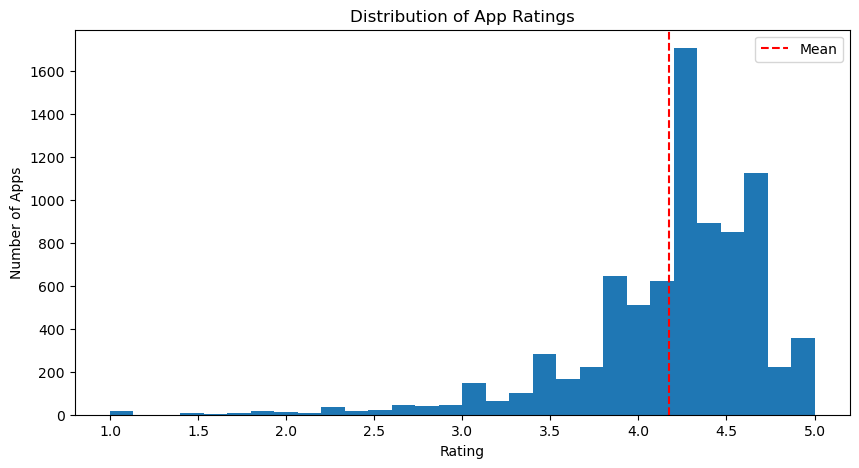

In [43]:
plt.figure(figsize=(10,5))
plt.hist(df['Rating'].dropna(), bins=30)
plt.axvline(avg_rating, color='red', linestyle='--', label='Mean')
plt.title('Distribution of App Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Apps')
plt.legend()
plt.show()

**Insight:** The average rating is **4.17** (median 4.3), so users are generally happy with their apps. The middle half of all apps are rated between 4.0 and 4.5. A new app should aim for at least this level to be considered average.

## Basic Q2. How many unique categories of apps are there?

In [46]:
print('Number of unique categories:', df['Category'].nunique())
category_count = df['Category'].value_counts()
category_count

Number of unique categories: 33


Category
Family                 1878
Game                    945
Tools                   829
Business                420
Medical                 395
Personalization         376
Productivity            374
Lifestyle               369
Finance                 345
Sports                  325
Communication           315
Health And Fitness      288
Photography             281
News And Magazines      254
Social                  239
Books And Reference     222
Travel And Local        219
Shopping                202
Dating                  170
Video Players           164
Maps And Navigation     131
Food And Drink          112
Education               105
Entertainment            86
Auto And Vehicles        85
Libraries And Demo       84
Weather                  79
House And Home           73
Events                   64
Art And Design           61
Parenting                60
Comics                   56
Beauty                   53
Name: count, dtype: int64

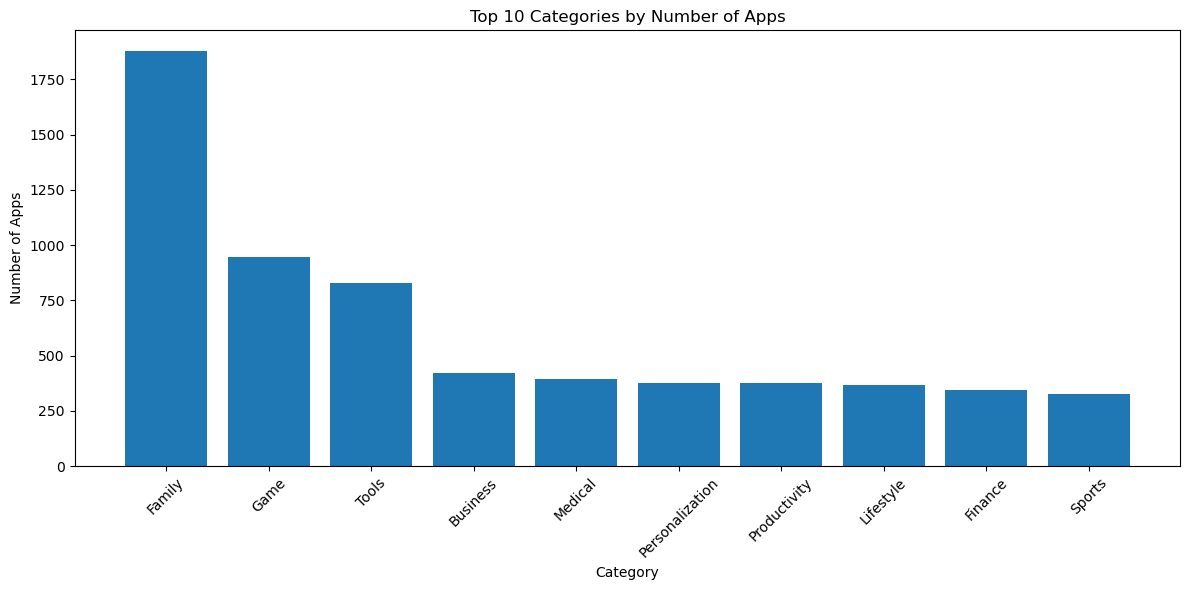

In [47]:
plt.figure(figsize=(12,6))
plt.bar(category_count.head(10).index, category_count.head(10).values)
plt.title('Top 10 Categories by Number of Apps')
plt.xlabel('Category')
plt.ylabel('Number of Apps')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Insight:** There are **33 unique categories**. **Family** has the most apps (1,876), followed by Game (946) and Tools (829). These are crowded markets, while categories at the bottom of the list have much less competition.

## Basic Q3. What is the distribution of app sizes?

In [50]:
df['Size_MB'].describe()

count    8431.000000
mean       20.398075
std        21.828959
min         0.008301
25%         4.600000
50%        12.000000
75%        28.000000
max       100.000000
Name: Size_MB, dtype: float64

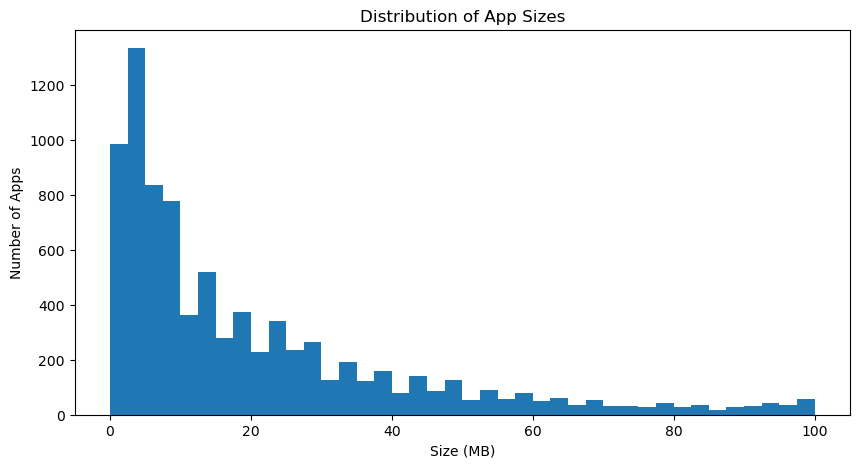

In [51]:
plt.figure(figsize=(10,5))
plt.hist(df['Size_MB'].dropna(), bins=40)
plt.title('Distribution of App Sizes')
plt.xlabel('Size (MB)')
plt.ylabel('Number of Apps')
plt.show()

**Insight:** Most apps are small. The median size is **12.0 MB** and the average is 20.4 MB, and **67%** of apps are under 30 MB. A few apps go up to 100 MB, which pulls the average above the median. (Size is missing for 1,228 apps marked 'Varies with device'.)

## Basic Q4. How many free vs paid apps are there?

In [54]:
type_count = df['Type'].value_counts()
type_count

Type
Free    8905
Paid     754
Name: count, dtype: int64

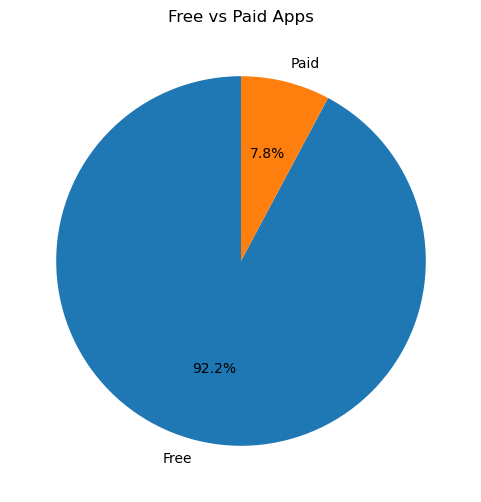

In [55]:
plt.figure(figsize=(6,6))
plt.pie(type_count.values, labels=type_count.index, autopct='%1.1f%%', startangle=90)
plt.title('Free vs Paid Apps')
plt.show()

**Insight:** **8,905 apps (92.2%)** are free and only **754** are paid. Most developers choose the free model and earn money in other ways (ads, in-app purchases).

## Basic Q5. What is the most common content rating for apps?

In [58]:
print('Most common content rating:', df['Content Rating'].mode()[0])
content_count = df['Content Rating'].value_counts()
content_count

Most common content rating: Everyone


Content Rating
Everyone           7903
Teen               1036
Mature 17+          393
Everyone 10+        322
Adults only 18+       3
Unrated               2
Name: count, dtype: int64

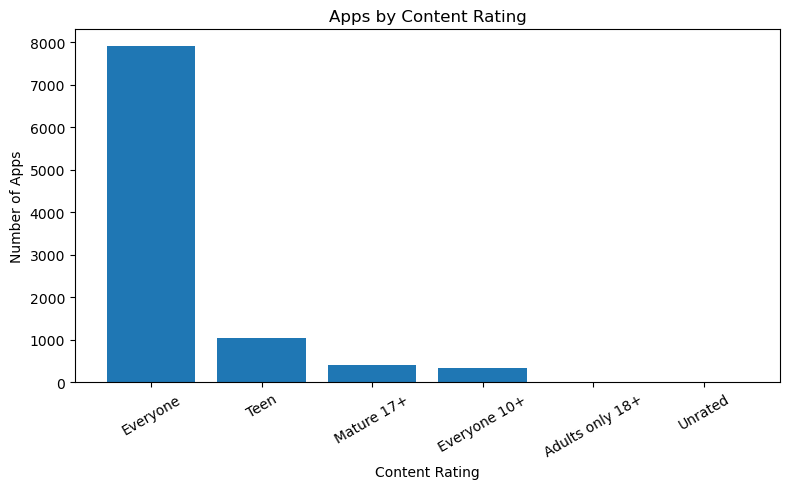

In [59]:
plt.figure(figsize=(8,5))
plt.bar(content_count.index, content_count.values)
plt.title('Apps by Content Rating')
plt.xlabel('Content Rating')
plt.ylabel('Number of Apps')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Insight:** **Everyone** is the most common content rating with 7,903 apps (82%), followed by Teen (1,036). Most apps are made for a general audience, so that is the biggest user base.

## Basic Q6. What are the top 5 most installed apps?

In [62]:
# many apps have 1,000,000,000+ installs, so I use Reviews to break the tie
top5_installed = df.sort_values(['Installs', 'Reviews'], ascending=False).head(5)
top5_installed[['App', 'Category', 'Installs', 'Reviews', 'Rating']]

,App,Category,Installs,Reviews,Rating
1872,Facebook,Social,1000000000,78158306,4.1
279,WhatsApp Messenger,Communication,1000000000,69119316,4.4
1913,Instagram,Social,1000000000,66577446,4.5
304,Messenger – Text and Video Chat for Free,Communication,1000000000,56646578,4.0
1349,Subway Surfers,Game,1000000000,27725352,4.5


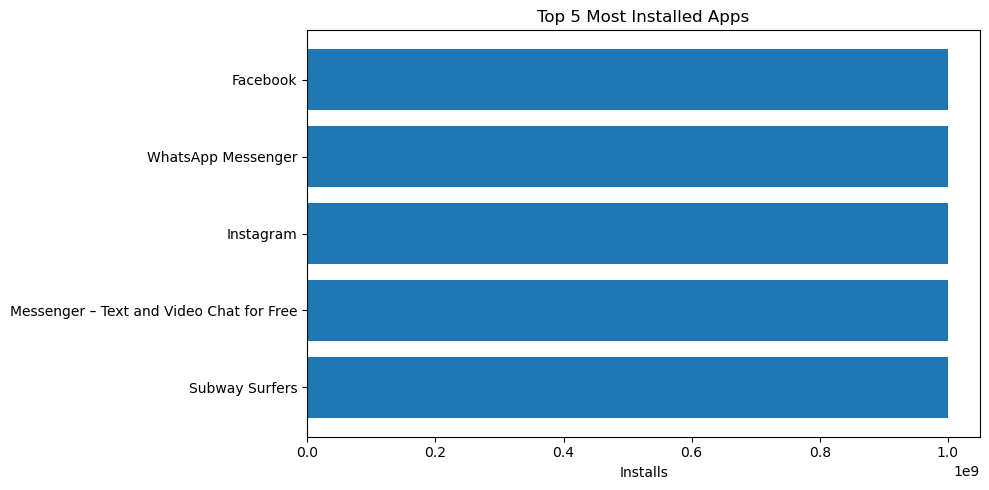

In [63]:
plt.figure(figsize=(10,5))
plt.barh(top5_installed['App'], top5_installed['Installs'])
plt.gca().invert_yaxis()
plt.title('Top 5 Most Installed Apps')
plt.xlabel('Installs')
plt.tight_layout()
plt.show()

**Insight:** The top apps are Facebook, WhatsApp Messenger, Instagram, Messenger – Text and Video Chat for Free, Subway Surfers. Note that **20 apps** are in the 1 billion+ band (the dataset only gives install ranges, not exact numbers), so this top 5 is decided by review count. All of them have ratings between 4.0 and 4.5, which means you do not need a perfect rating to get a huge number of installs.

## Basic Q7. How many apps have a rating of 4.0 and above?

In [66]:
high_rated = (df['Rating'] >= 4.0).sum()
rated_apps = df['Rating'].notnull().sum()
print('Apps with rating >= 4.0:', high_rated)
print('Percentage of rated apps:', round(high_rated / rated_apps * 100, 1), '%')

Apps with rating >= 4.0: 6287
Percentage of rated apps: 76.7 %


**Insight:** **6,287 apps** have a rating of 4.0 or above. That is **76.7%** of the 8,196 apps that have a rating. So 4.0 is the normal level in this store and a new app needs to be better than 4.0 to stand out.

## Basic Q8. What is the average number of reviews for free vs paid apps?

In [69]:
reviews_by_type = df.groupby('Type')['Reviews'].agg(['mean', 'median'])
reviews_by_type

,mean,median
Type,,
Free,234420.539248,1379.0
Paid,8748.010610,88.5


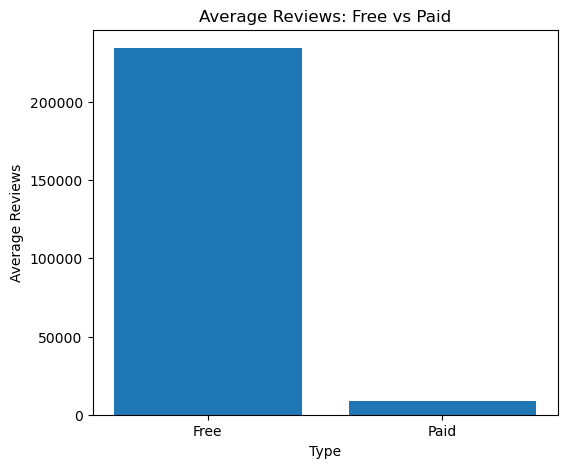

In [70]:
plt.figure(figsize=(6,5))
plt.bar(reviews_by_type.index, reviews_by_type['mean'])
plt.title('Average Reviews: Free vs Paid')
plt.xlabel('Type')
plt.ylabel('Average Reviews')
plt.show()

**Insight:** Free apps get far more reviews - an average of **234,421** compared to **8,748** for paid apps. The median shows the same story (1,379 vs 88). The average is pushed up by a few very famous apps, but free apps clearly get more user engagement.

## Basic Q9. What is the average app size for each category?

In [73]:
size_by_category = df.groupby('Category')['Size_MB'].mean().sort_values(ascending=False)
size_by_category.head(10)

Category
Game                  41.682481
Family                27.304921
Travel And Local      24.204375
Sports                24.058153
Entertainment         23.707143
Parenting             22.512963
Health And Fitness    20.669296
Food And Drink        20.494318
Auto And Vehicles     20.036807
Medical               19.188485
Name: Size_MB, dtype: float64

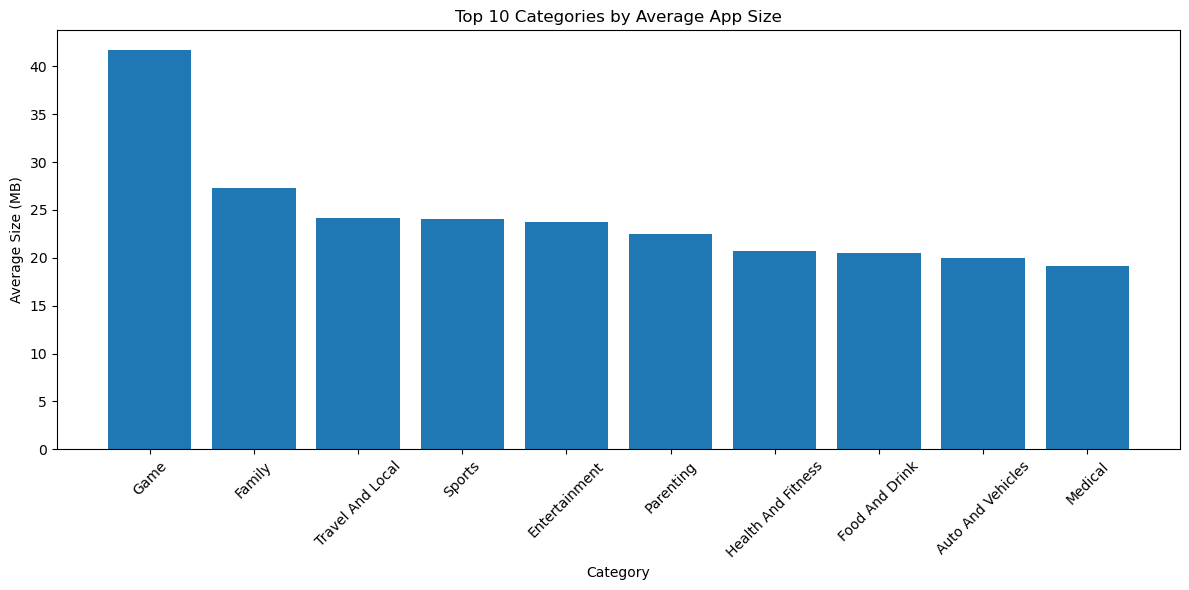

In [74]:
plt.figure(figsize=(12,6))
plt.bar(size_by_category.head(10).index, size_by_category.head(10).values)
plt.title('Top 10 Categories by Average App Size')
plt.xlabel('Category')
plt.ylabel('Average Size (MB)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [75]:
# smallest categories
size_by_category.tail(5)

Category
Art And Design        12.237288
Communication         11.306306
Personalization       11.223880
Libraries And Demo    10.598851
Tools                  8.770229
Name: Size_MB, dtype: float64

**Insight:** **Game** apps are the biggest on average (41.7 MB), followed by Family and Travel And Local. The smallest are Tools (8.8 MB) and Libraries And Demo. Games need more space because of graphics, while tools and simple apps stay light.

## Basic Q10. How many apps were last updated in 2018?

In [78]:
apps_2018 = (df['Updated_Year'] == 2018).sum()
print('Apps last updated in 2018:', apps_2018)
print('Percentage of all apps:', round(apps_2018 / len(df) * 100, 1), '%')

Apps last updated in 2018: 6287
Percentage of all apps: 65.1 %


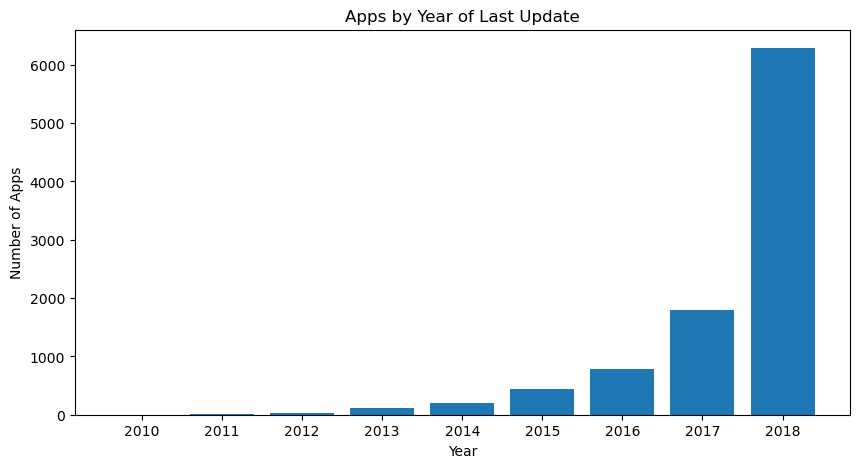

In [79]:
year_count = df['Updated_Year'].value_counts().sort_index()

plt.figure(figsize=(10,5))
plt.bar(year_count.index.astype(str), year_count.values)
plt.title('Apps by Year of Last Update')
plt.xlabel('Year')
plt.ylabel('Number of Apps')
plt.show()

**Insight:** **6,287 apps (65%)** were last updated in 2018. The dataset was collected in August 2018, so most apps on the store have been updated fairly recently.

# Medium Level Questions

## Medium Q1. What is the correlation between the number of installs and the app rating?

In [83]:
df['Installs'].corr(df['Rating'])

0.04024460734455512

In [84]:
# installs have a huge range, so I also check using log of installs
df['Log_Installs'] = np.log10(df['Installs'] + 1)
df['Log_Installs'].corr(df['Rating'])

0.08475180914540116

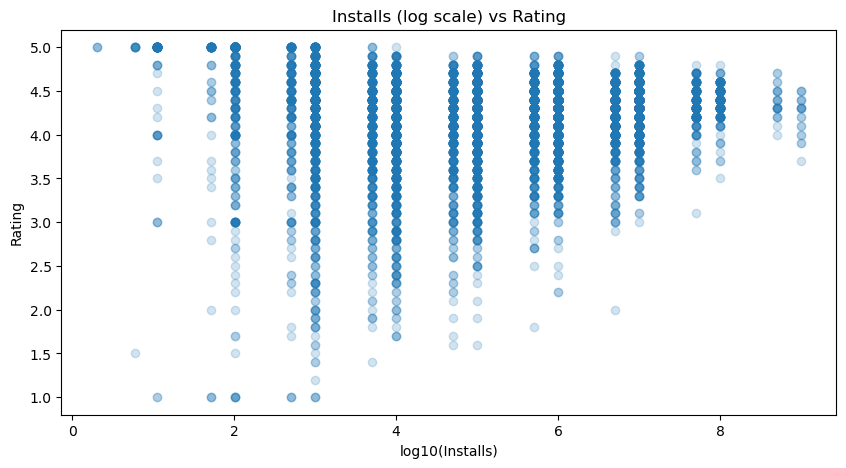

In [85]:
plt.figure(figsize=(10,5))
plt.scatter(df['Log_Installs'], df['Rating'], alpha=0.2)
plt.title('Installs (log scale) vs Rating')
plt.xlabel('log10(Installs)')
plt.ylabel('Rating')
plt.show()

**Insight:** The correlation is only **0.04** (and 0.08 on log scale). This is very weak - an app with more installs is not necessarily better rated. So ratings alone do not drive downloads; marketing and the app's category matter too.

## Medium Q2. Which app categories have the highest average rating?

In [88]:
avg_rating_cat = df.groupby('Category')['Rating'].mean().sort_values(ascending=False)
avg_rating_cat.head(10)

Category
Events                 4.435556
Art And Design         4.359322
Education              4.349038
Books And Reference    4.344970
Personalization        4.332215
Parenting              4.300000
Beauty                 4.278571
Social                 4.247291
Game                   4.244432
Weather                4.243056
Name: Rating, dtype: float64

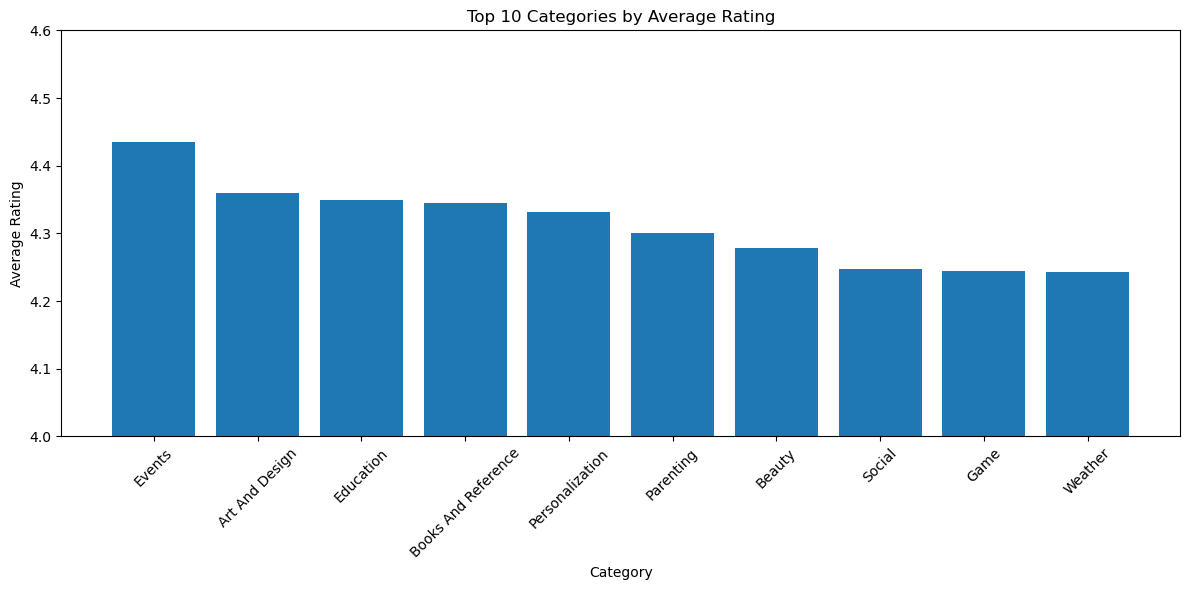

In [89]:
plt.figure(figsize=(12,6))
plt.bar(avg_rating_cat.head(10).index, avg_rating_cat.head(10).values)
plt.title('Top 10 Categories by Average Rating')
plt.xlabel('Category')
plt.ylabel('Average Rating')
plt.ylim(4, 4.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Insight:** **Events** has the highest average rating (4.44), followed by Art And Design (4.36) and Education (4.35). The lowest is Dating (3.98). The gap between top and bottom is small, so category matters but only a little.

## Medium Q3. How does the price of an app affect its average rating?

In [92]:
paid_apps = df[df['Type'] == 'Paid'].copy()
price_rating = paid_apps.groupby('Price')['Rating'].mean()
price_rating.head(10)

Price
0.99    4.298077
1.00    4.450000
1.04         NaN
1.20    4.200000
1.26         NaN
1.29    4.100000
1.49    4.196774
1.50    4.200000
1.59    4.500000
1.61    4.200000
Name: Rating, dtype: float64

In [93]:
print('Correlation between price and rating:', round(paid_apps['Price'].corr(paid_apps['Rating']), 3))

Correlation between price and rating: -0.114


In [94]:
# there are too many different prices, so I also group them into price bands
paid_apps['Price_Band'] = pd.cut(paid_apps['Price'], bins=[0, 1, 2, 5, 10, 500],
                                 labels=['Up to $1', '$1-2', '$2-5', '$5-10', 'Above $10'])
band_rating = paid_apps.groupby('Price_Band', observed=True)['Rating'].mean()
band_rating

Price_Band
Up to $1     4.300943
$1-2         4.292079
$2-5         4.263830
$5-10        4.258621
Above $10    4.127273
Name: Rating, dtype: float64

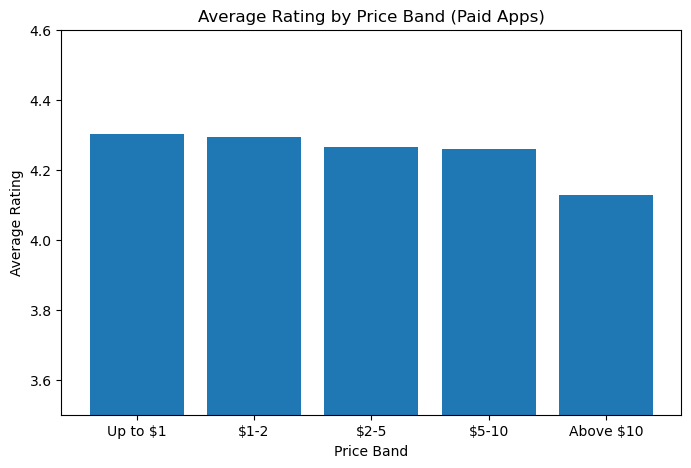

In [95]:
plt.figure(figsize=(8,5))
plt.bar(band_rating.index.astype(str), band_rating.values)
plt.title('Average Rating by Price Band (Paid Apps)')
plt.xlabel('Price Band')
plt.ylabel('Average Rating')
plt.ylim(3.5, 4.6)
plt.show()

**Insight:** The correlation between price and rating is very small (**-0.11**). Apps priced up to $5 are rated about 4.3 on average, while apps above $10 get **4.13**. So charging a higher price does not make users rate the app higher - the most expensive apps are actually rated a bit lower.

## Medium Q4. What is the distribution of app ratings across different content ratings?

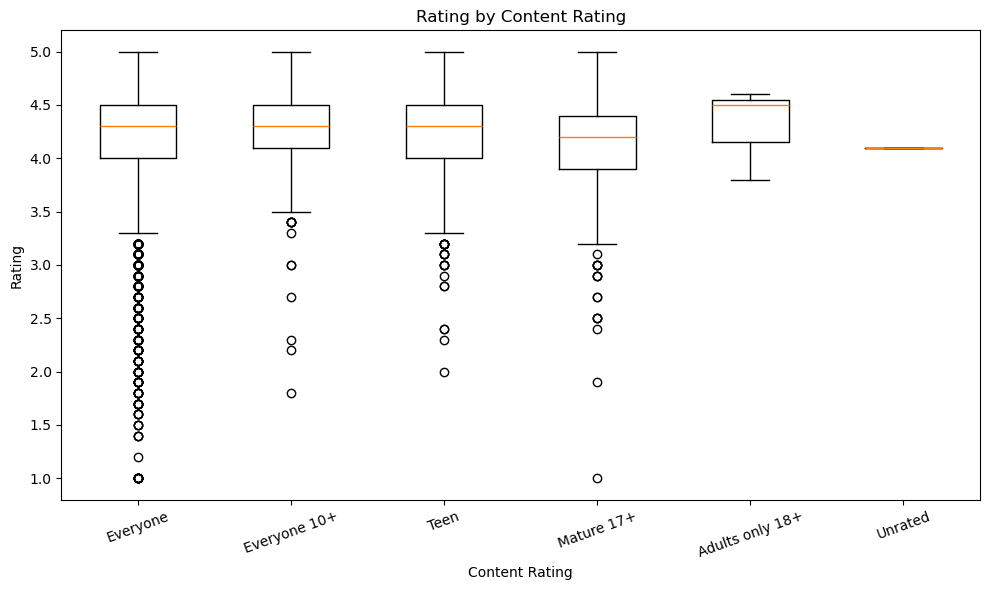

In [98]:
order = ['Everyone', 'Everyone 10+', 'Teen', 'Mature 17+', 'Adults only 18+', 'Unrated']
rating_data = [df[df['Content Rating'] == c]['Rating'].dropna() for c in order]

plt.figure(figsize=(10,6))
plt.boxplot(rating_data)
plt.xticks(range(1, len(order) + 1), order, rotation=20)
plt.title('Rating by Content Rating')
plt.xlabel('Content Rating')
plt.ylabel('Rating')
plt.tight_layout()
plt.show()

In [99]:
df.groupby('Content Rating')['Rating'].agg(['mean', 'median', 'count'])

,mean,median,count
Content Rating,,,
Adults only 18+,4.300000,4.5,3
Everyone,4.166349,4.3,6618
Everyone 10+,4.225902,4.3,305
Mature 17+,4.121849,4.2,357
Teen,4.225658,4.3,912
Unrated,4.100000,4.1,1


**Insight:** The boxes look very similar for all groups, so content rating has little effect on ratings. 'Everyone' apps average 4.17 and 'Teen' apps 4.23. 'Adults only 18+' and 'Unrated' have only a few apps, so their numbers are not reliable.

## Medium Q5. Which genres have the most apps with over 1 million installs?

In [102]:
# the Installs column is a range like '1,000,000+', so I take 1,000,000 and above
big_apps = df[df['Installs'] >= 1000000]
print('Apps with 1M+ installs:', len(big_apps))
genre_big = big_apps['Main_Genre'].value_counts()
genre_big.head(10)

Apps with 1M+ installs: 3398


Main_Genre
Tools               275
Action              189
Entertainment       179
Photography         173
Productivity        147
Communication       140
Sports              125
Casual              122
Arcade              118
Health & Fitness    113
Name: count, dtype: int64

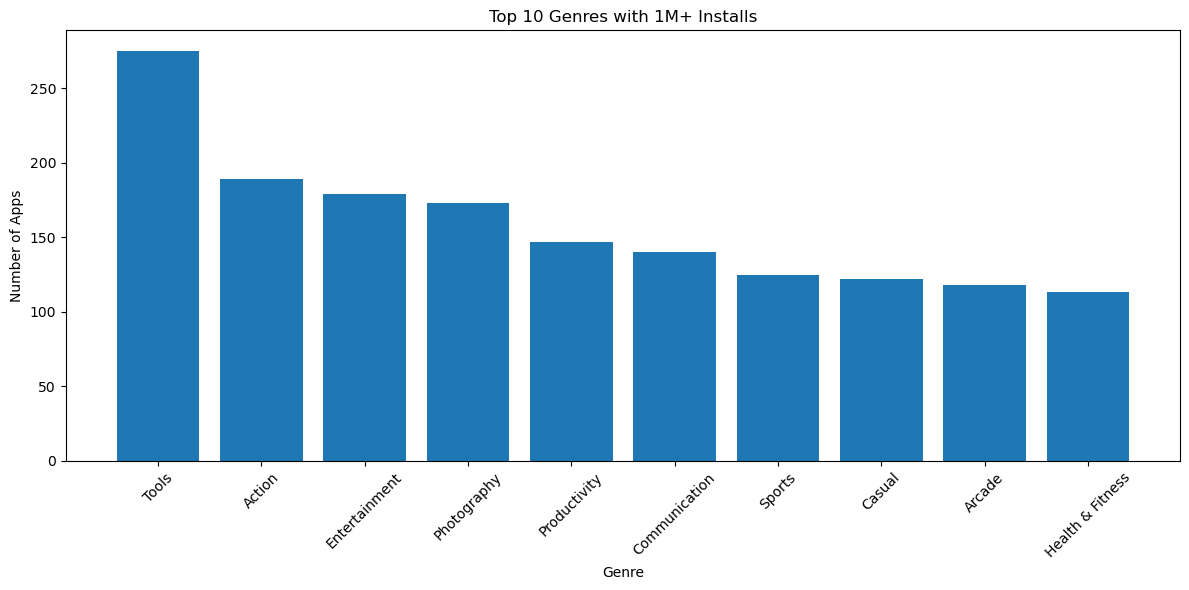

In [103]:
plt.figure(figsize=(12,6))
plt.bar(genre_big.head(10).index, genre_big.head(10).values)
plt.title('Top 10 Genres with 1M+ Installs')
plt.xlabel('Genre')
plt.ylabel('Number of Apps')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Insight:** **Tools** has the most apps with 1M+ installs (275), followed by Action (189) and Entertainment (179). These genres have the highest demand.

## Medium Q6. How frequently do apps get updated?

Each app appears only once in the data, so it has only one `Last Updated` date and I cannot subtract consecutive updates of the same app. Instead I calculate **how many days ago each app was last updated** (compared to the newest date in the data). A smaller number means the app is updated more often.

In [107]:
latest_date = df['Last Updated'].max()
df['Days_Since_Update'] = (latest_date - df['Last Updated']).dt.days

print('Latest date in data:', latest_date.date())
print('Average days since last update:', round(df['Days_Since_Update'].mean(), 1))
print('Median days since last update :', df['Days_Since_Update'].median())

Latest date in data: 2018-08-08
Average days since last update: 281.0
Median days since last update : 96.0


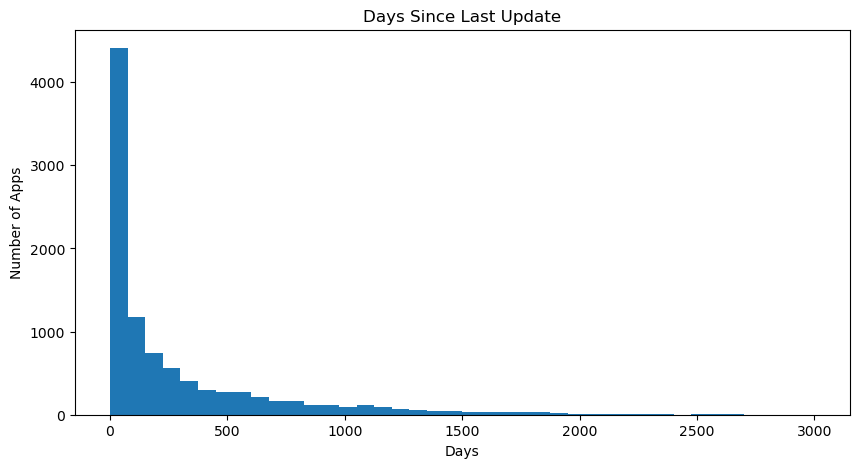

In [108]:
plt.figure(figsize=(10,5))
plt.hist(df['Days_Since_Update'], bins=40)
plt.title('Days Since Last Update')
plt.xlabel('Days')
plt.ylabel('Number of Apps')
plt.show()

In [109]:
# share of apps updated in the last 30 days and not updated for over a year
print('Updated within 30 days :', round((df['Days_Since_Update'] <= 30).mean() * 100, 1), '%')
print('Not updated for 1+ year:', round((df['Days_Since_Update'] > 365).mean() * 100, 1), '%')

Updated within 30 days : 30.4 %
Not updated for 1+ year: 25.0 %


**Insight:** On average an app was last updated **281 days** before the data was collected (median 96 days). **30%** of apps were updated in the last month, but **25%** have not been updated for over a year. A regular update plan (every 1 to 3 months) keeps an app in the more active group.

## Medium Q7. What is the impact of app size on the number of installs?

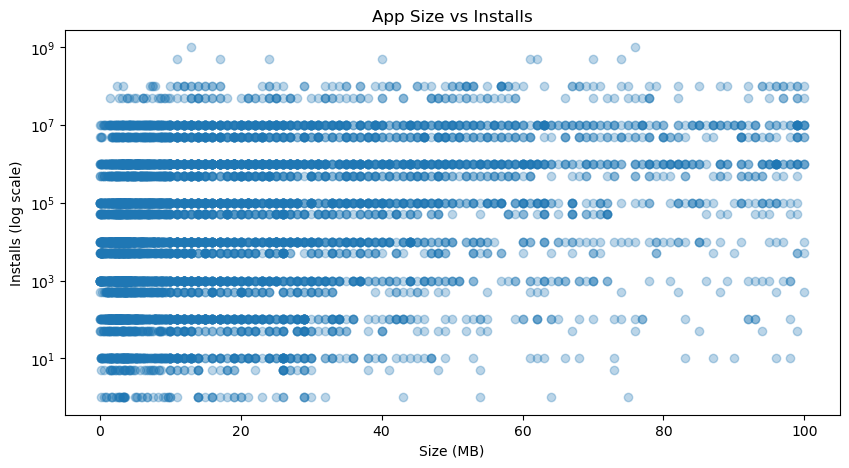

In [112]:
plt.figure(figsize=(10,5))
plt.scatter(df['Size_MB'], df['Installs'], alpha=0.3)
plt.yscale('log')
plt.title('App Size vs Installs')
plt.xlabel('Size (MB)')
plt.ylabel('Installs (log scale)')
plt.show()

In [113]:
print('Correlation between size and installs:', round(df['Size_MB'].corr(df['Installs']), 3))

# median installs for each size group
size_group = pd.cut(df['Size_MB'], bins=[0, 5, 10, 20, 50, 100],
                    labels=['Under 5 MB', '5-10 MB', '10-20 MB', '20-50 MB', '50-100 MB'])
size_group_installs = df.groupby(size_group, observed=True)['Installs'].median()
size_group_installs

Correlation between size and installs: 0.134


Size_MB
Under 5 MB       5000.0
5-10 MB         10000.0
10-20 MB        50000.0
20-50 MB       100000.0
50-100 MB     1000000.0
Name: Installs, dtype: float64

**Insight:** The scatter plot shows no strong pattern and the correlation is low (**0.13**), so apps of every size can reach high installs. Still, the median installs go up with size - from 5,000 for apps under 5 MB to 1,000,000 for apps of 50-100 MB. This is probably because big apps like games and social apps are heavily downloaded. So a bigger size does not stop people from installing an app.

## Medium Q8. Which apps have the highest number of reviews, and what are their ratings?

In [116]:
top_reviews = df.sort_values('Reviews', ascending=False).head(10)
top_reviews[['App', 'Category', 'Reviews', 'Rating', 'Installs']]

,App,Category,Reviews,Rating,Installs
1872,Facebook,Social,78158306,4.1,1000000000
279,WhatsApp Messenger,Communication,69119316,4.4,1000000000
1913,Instagram,Social,66577446,4.5,1000000000
304,Messenger – Text and Video Chat for Free,Communication,56646578,4.0,1000000000
1354,Clash of Clans,Game,44893888,4.6,100000000
3022,Clean Master- Space Cleaner & Antivirus,Tools,42916526,4.7,500000000
1349,Subway Surfers,Game,27725352,4.5,1000000000
2749,YouTube,Video Players,25655305,4.3,1000000000
6382,"Security Master - Antivirus, VPN, AppLock, Boo...",Tools,24900999,4.7,500000000
1353,Clash Royale,Game,23136735,4.6,100000000


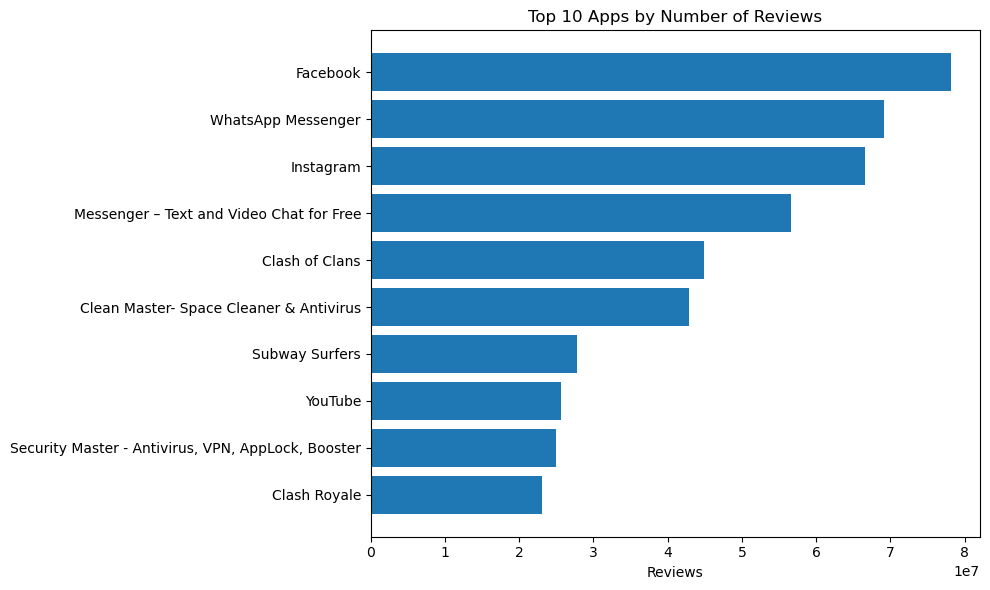

In [117]:
plt.figure(figsize=(10,6))
plt.barh(top_reviews['App'], top_reviews['Reviews'])
plt.gca().invert_yaxis()
plt.title('Top 10 Apps by Number of Reviews')
plt.xlabel('Reviews')
plt.tight_layout()
plt.show()

**Insight:** **Facebook** has the most reviews (78,158,306), then WhatsApp Messenger and Instagram. All of these top-10 apps are rated between 4.0 and 4.7, and all have 100M+ installs. Very popular apps collect a lot of reviews and still keep good ratings.

## Medium Q9. How does the content rating distribution differ between free and paid apps?

In [120]:
content_type = pd.crosstab(df['Content Rating'], df['Type'])
content_type

Type,Free,Paid
Content Rating,,
Adults only 18+,3,0
Everyone,7250,653
Everyone 10+,291,31
Mature 17+,375,18
Teen,984,52
Unrated,2,0


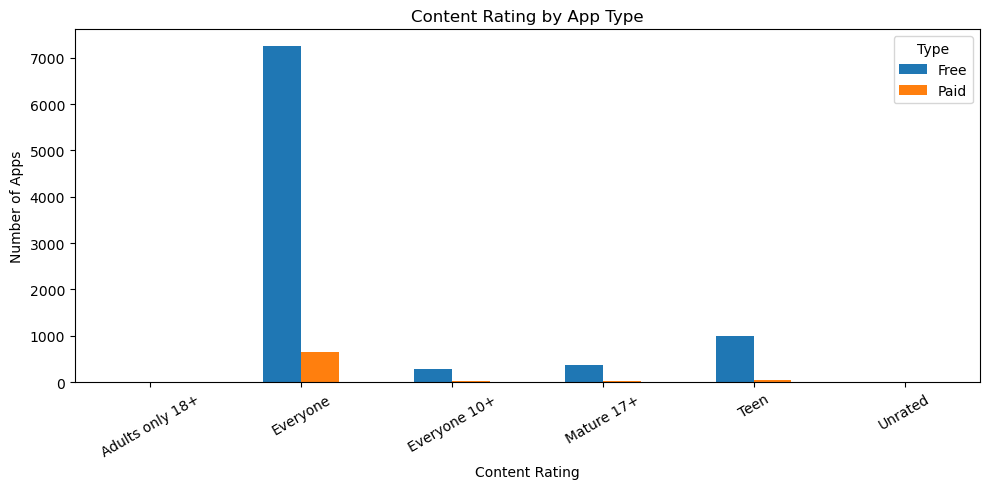

In [121]:
content_type.plot(kind='bar', figsize=(10,5))
plt.title('Content Rating by App Type')
plt.xlabel('Content Rating')
plt.ylabel('Number of Apps')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [122]:
# same thing in percentage for each type
pd.crosstab(df['Content Rating'], df['Type'], normalize='columns').round(3) * 100

Type,Free,Paid
Content Rating,,
Adults only 18+,0.0,0.0
Everyone,81.4,86.6
Everyone 10+,3.3,4.1
Mature 17+,4.2,2.4
Teen,11.0,6.9
Unrated,0.0,0.0


**Insight:** 'Everyone' is the biggest group in both types - 81% of free apps and 87% of paid apps. Paid apps have a slightly higher share of 'Everyone' apps and fewer 'Teen' apps than free apps, so the audience is quite similar for both.

## Medium Q10. What are the top 5 categories with the most installs?

In [125]:
category_installs = df.groupby('Category')['Installs'].sum().sort_values(ascending=False)
category_installs.head(5)

Category
Game             13447924415
Communication    11038276251
Tools             8102771915
Family            6237542505
Productivity      5793091369
Name: Installs, dtype: int64

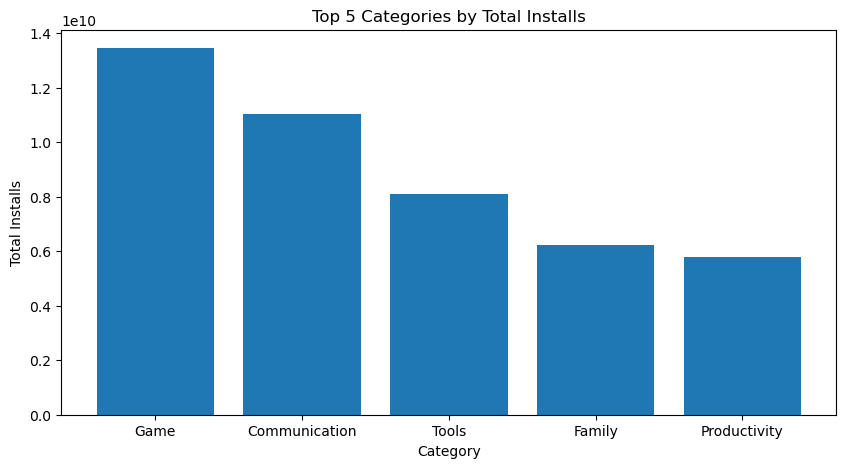

In [126]:
plt.figure(figsize=(10,5))
plt.bar(category_installs.head(5).index, category_installs.head(5).values)
plt.title('Top 5 Categories by Total Installs')
plt.xlabel('Category')
plt.ylabel('Total Installs')
plt.show()

**Insight:** The top 5 categories are **Game, Communication, Tools, Family, Productivity**. **Game** is far ahead with about 13.5 billion installs. These categories have the highest user demand.

# Advanced Level Questions

## Advanced Q1. What are the top 10 apps with the highest ratings, and how do their reviews and installs compare?

In [130]:
top_rated = df.sort_values('Rating', ascending=False).head(10)
top_rated[['App', 'Rating', 'Reviews', 'Installs']]

,App,Rating,Reviews,Installs
4140,AJ Cam,5.0,44,100
8088,EC Mover,5.0,5,10
5505,Bar-B-Q Rib House,5.0,2,50
8164,EG India,5.0,3,100
8124,EF Academy,5.0,4,50
8116,EF App,5.0,8,100
8113,EF Forms,5.0,2,50
8105,EF Events,5.0,7,100
8077,EC Fairgrounds,5.0,3,500
5466,MI-BP,5.0,1,50


Many apps have a perfect 5.0, but a plain sort gives apps with only a handful of reviews. To make it fair, I only look at apps with at least 1,000 reviews.

In [132]:
top_rated_fair = df[df['Reviews'] >= 1000].sort_values(['Rating', 'Reviews'], ascending=False).head(10)
top_rated_fair[['App', 'Category', 'Rating', 'Reviews', 'Installs']]

,App,Category,Rating,Reviews,Installs
8448,JW Library,Books And Reference,4.9,922752,10000000
936,Six Pack in 30 Days - Abs Workout,Health And Fitness,4.9,272337,10000000
75,Tickets + PDA 2018 Exam,Auto And Vehicles,4.9,197136,1000000
531,"Learn Japanese, Korean, Chinese Offline & Free",Education,4.9,133136,1000000
975,StrongLifts 5x5 Workout Gym Log & Personal Tra...,Health And Fitness,4.9,66791,1000000
5852,PixPanda - Color by Number Pixel Art Coloring ...,Family,4.9,55723,1000000
95,"ipsy: Makeup, Beauty, and Tips",Beauty,4.9,49790,1000000
2969,Hungry Hearts Diner: A Tale of Star-Crossed Souls,Family,4.9,46253,500000
934,Lose Belly Fat in 30 Days - Flat Stomach,Health And Fitness,4.9,38098,5000000
3893,Solitaire: Decked Out Ad Free,Game,4.9,37302,500000


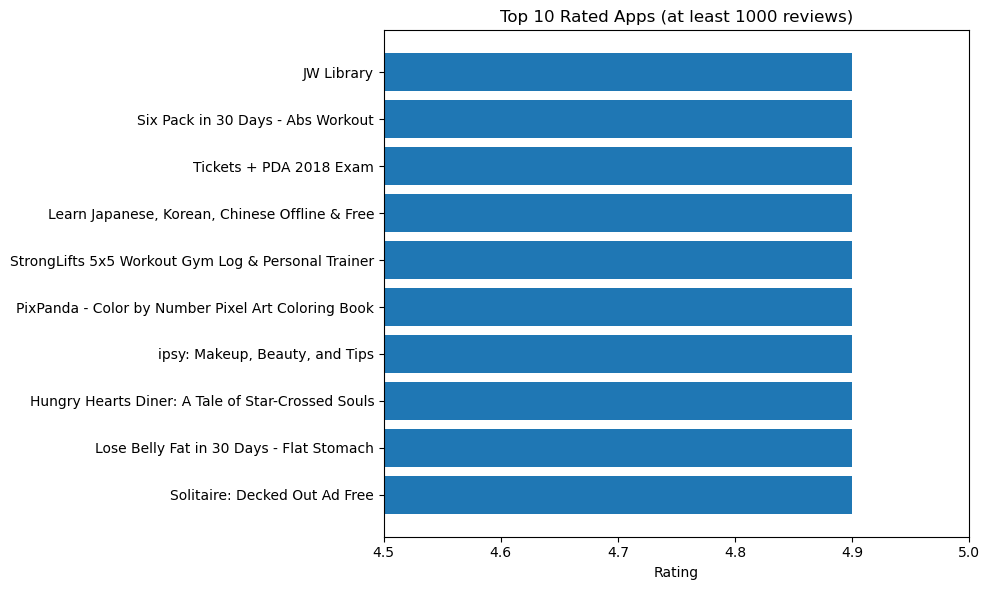

In [133]:
plt.figure(figsize=(10,6))
plt.barh(top_rated_fair['App'], top_rated_fair['Rating'])
plt.gca().invert_yaxis()
plt.xlim(4.5, 5)
plt.title('Top 10 Rated Apps (at least 1000 reviews)')
plt.xlabel('Rating')
plt.tight_layout()
plt.show()

**Insight:** A plain sort is misleading. There are **271 apps with a 5.0 rating**, but their median review count is only **4**. Once we need at least 1,000 reviews, the best apps all have a rating of about 4.9, with 37,302 to 922,752 reviews. Their installs are between 500,000 and 10,000,000, so the best-rated apps are mid-sized apps and not the most downloaded ones.

## Advanced Q2. Analyze the trend of app updates over time. Are there any patterns or seasonal trends?

In [136]:
recent = df[df['Last Updated'] >= '2017-01-01']
monthly_updates = recent.groupby(recent['Last Updated'].dt.to_period('M')).size()
monthly_updates

Last Updated
2017-01      98
2017-02     127
2017-03     128
2017-04      90
2017-05     121
2017-06     111
2017-07     134
2017-08     160
2017-09     158
2017-10     213
2017-11     205
2017-12     247
2018-01     286
2018-02     297
2018-03     408
2018-04     394
2018-05     690
2018-06     911
2018-07    2318
2018-08     983
Freq: M, dtype: int64

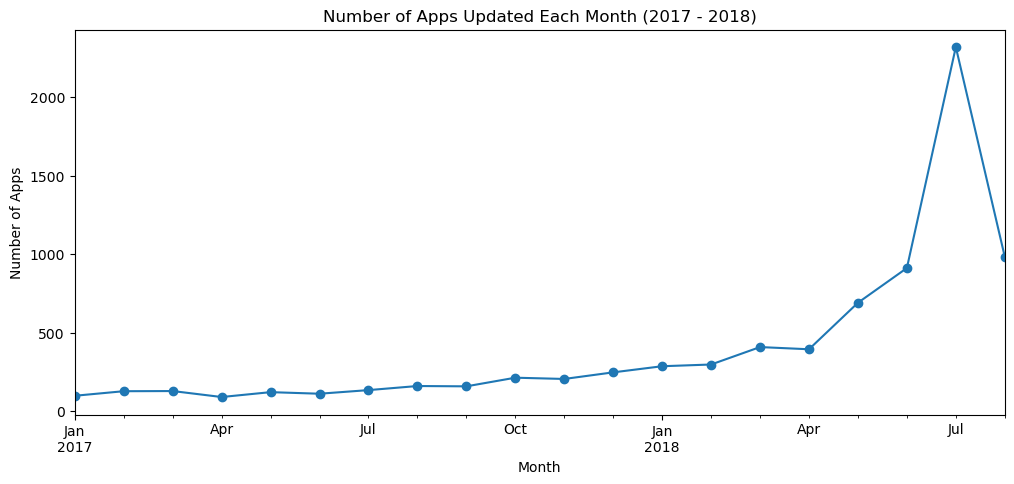

In [137]:
plt.figure(figsize=(12,5))
monthly_updates.plot(kind='line', marker='o')
plt.title('Number of Apps Updated Each Month (2017 - 2018)')
plt.xlabel('Month')
plt.ylabel('Number of Apps')
plt.show()

**Insight:** The number of apps whose last update falls in a month rises through 2017 and 2018, and the highest month is **2018-07** with **2,318** apps. Part of this is simply because older updates get replaced by newer ones, so recent months always look bigger. The data stops in August 2018, so we cannot see a full yearly cycle, and no clear seasonal pattern can be confirmed. Developers should plan updates regularly instead of waiting for a particular season.

## Advanced Q3. How does the average rating change with the number of installs? (binned analysis)

In [140]:
install_bins = [0, 1000, 10000, 100000, 1000000, 10000000, 100000000, 10000000000]
install_labels = ['Under 1K', '1K-10K', '10K-100K', '100K-1M', '1M-10M', '10M-100M', '100M+']

df['Install_Bin'] = pd.cut(df['Installs'], bins=install_bins, labels=install_labels, right=False)
rating_by_bin = df.groupby('Install_Bin', observed=True)['Rating'].agg(['mean', 'count'])
rating_by_bin

,mean,count
Install_Bin,,
Under 1K,4.345298,638
1K-10K,4.048617,1121
10K-100K,4.038115,1443
100K-1M,4.132416,1598
1M-10M,4.220030,2022
10M-100M,4.304557,1141
100M+,4.370386,233


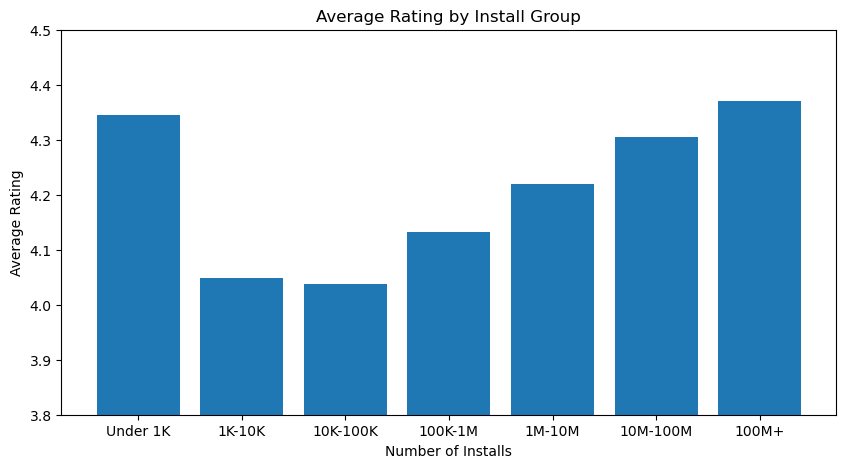

In [141]:
plt.figure(figsize=(10,5))
plt.bar(rating_by_bin.index.astype(str), rating_by_bin['mean'])
plt.title('Average Rating by Install Group')
plt.xlabel('Number of Installs')
plt.ylabel('Average Rating')
plt.ylim(3.8, 4.5)
plt.show()

**Insight:** Average rating is lowest for apps with 1K-100K installs (about 4.04) and then goes up as apps become more popular, reaching **4.37** for apps with 100M+ installs. Apps with under 1K installs look high (4.35), but they have very few ratings so that number is not very reliable. In short, apps that grow to a large user base are generally the ones that users like.

## Advanced Q4. Sentiment analysis of app reviews

This dataset (`googleplaystore.csv`) only has the **number** of reviews for each app and not the review text, so sentiment analysis cannot be done with this data alone. The question says "if review text is available", so I am skipping it here. If the review text is needed, it would have to come from a separate reviews dataset.

## Advanced Q5. What is the relationship between app genre and user ratings?

In [146]:
genre_rating = df.groupby('Main_Genre')['Rating'].agg(['mean', 'median', 'count'])

# only genres which have at least 20 rated apps, so that small genres do not mislead
genre_rating = genre_rating[genre_rating['count'] >= 20].sort_values('mean', ascending=False)
genre_rating.head(10)

,mean,median,count
Main_Genre,,,
Events,4.435556,4.5,45
Puzzle,4.370732,4.4,123
Art & Design,4.350000,4.4,62
Books & Reference,4.343275,4.5,171
Personalization,4.332215,4.4,298
Word,4.318182,4.3,22
Parenting,4.300000,4.4,50
Education,4.293574,4.4,498
Board,4.291228,4.3,57


In [147]:
# lowest rated genres
genre_rating.tail(5)

,mean,median,count
Main_Genre,,,
Video Players & Editors,4.044667,4.20,150
Tools,4.040278,4.20,720
Trivia,4.039286,4.25,28
Maps & Navigation,4.036441,4.20,118
Dating,3.980451,4.10,133


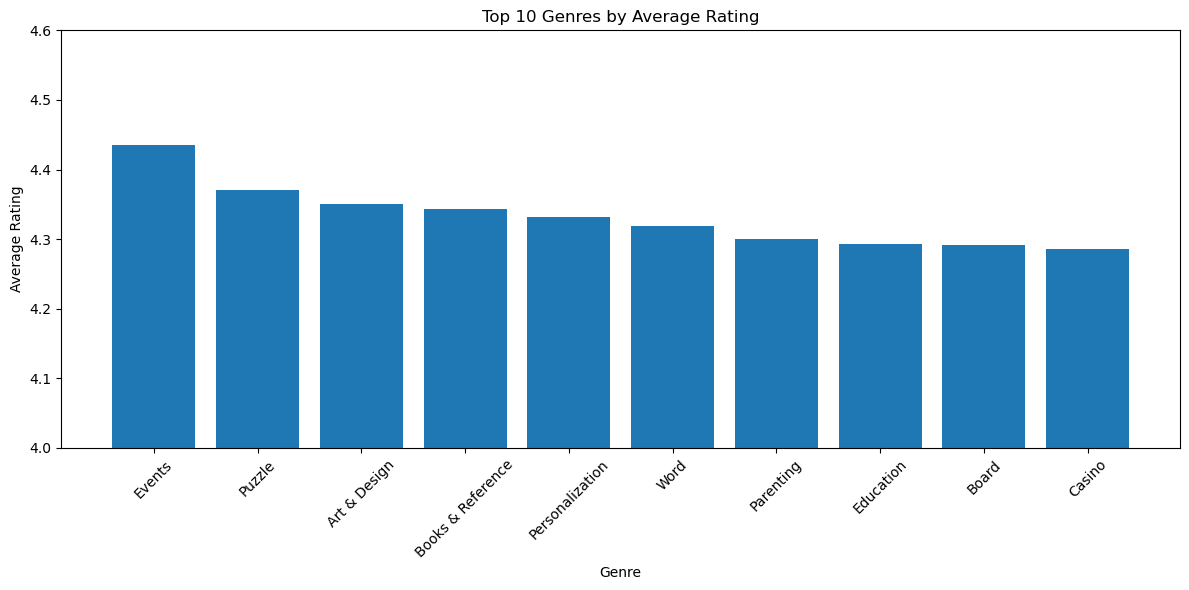

In [148]:
plt.figure(figsize=(12,6))
plt.bar(genre_rating.head(10).index, genre_rating.head(10)['mean'])
plt.title('Top 10 Genres by Average Rating')
plt.xlabel('Genre')
plt.ylabel('Average Rating')
plt.ylim(4, 4.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Insight:** **Events** (4.44), Puzzle (4.37) and Art & Design (4.35) are the best-rated genres, while **Dating** (3.98) and Maps & Navigation (4.04) are at the bottom. The medians follow the same pattern (about 4.4-4.5 for the top genres and 4.1-4.25 for the bottom ones), so these differences are not caused by a few apps. The gap is small (about 0.5 points), but it shows which genres users are happier with.

# Key Findings

- The average app rating is **4.17** and **77%** of rated apps are 4.0 or above, so 4.0 is only the minimum benchmark.
- **Family** has the most apps (1,876), but **Game** has the most installs (about 13.5 billion).
- **92%** of apps are free, and free apps get far more reviews than paid apps.
- Rating and installs are almost unrelated (correlation 0.04), and so are price and rating, and size and installs (all weak). No single number guarantees success.
- **Events** is the highest rated category (4.44), but the gap between categories is small.
- Most apps are small (median 12 MB), and 30% of apps were updated in the last month of the data.
- Apps with 1K-100K installs have the lowest ratings, and ratings improve for apps with 10M+ installs.

# Recommendations

1. **Aim for a rating above 4.3**, not just 4.0, because 4.0 is already normal in this store.
2. **Choose the category carefully.** Game, Communication and Tools bring the most installs, while categories like Events, Education and Art & Design have fewer apps and are very well rated.
3. **Prefer a free (freemium) model.** Free apps reach many more users and collect many more reviews. If an app is paid, keep the price low (under $5), because the most expensive apps get slightly lower ratings.
4. **Keep the app size reasonable.** Size has only a weak link with installs, so there is no need to cut useful features, but big apps like games should justify the download.
5. **Update regularly** so the app is in the active group and not among the apps that are not updated for a year.
6. **Ask users for reviews.** The most installed apps also have the most reviews, and reviews build trust for new users.

# Conclusion

From this analysis I found that app success on the Play Store does not depend on one thing. Category, pricing model, regular updates and user satisfaction all matter, but none of them guarantees installs by itself. A company that builds a good quality app (rating above 4.3) in the right category, offers it free or at a low price, and keeps updating it has the best chance of getting more installs and revenue.

*- Shubham Shah*